In [1]:
import matplotlib.pyplot as plt 
import numpy as np

import torch 
import torch.nn.functional as F
import torch.nn as nn

In [2]:
from sklearn.datasets import make_classification

In [3]:
X,y= make_classification(300,2,n_redundant=0,n_classes=2)

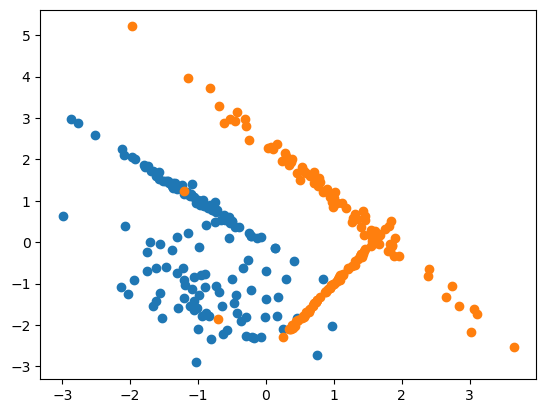

In [4]:
plt.scatter(X[y==0,0],X[y==0,1])
plt.scatter(X[y==1,0],X[y==1,1])


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
class LogisticRegressor(nn.Module):
    def __init__(self,num_of_features):
        super().__init__()
        self.num_of_features = num_of_features
        self.weights = torch.ones(1,num_of_features,dtype=torch.float32,device=device)
        self.bias = torch.zeros(1,dtype=torch.float32,device=device)
    def forward(self,X:torch.Tensor):
        linear= self.weights@X+self.bias
        probas = F.sigmoid(linear)
        return probas
    def backward(self,x,y,probas):
        grad_loss_out = probas.view(-1)-y 
        print(grad_loss_out)
        #grad_loss_w = grad_loss_out@x
        #print(grad_loss_w)
        #grad_loss_b = torch.sum(grad_loss_out)
        #print(grad_loss_b)
        #return grad_loss_w,grad_loss_b
    def predict_labels(self,x):
        probas =self.forward(x)
        label = torch.where(probas<.5,0,1)
        return label
    def evaulate(self,x,y):
        labels = self.predict_labels(x).float()
        accuarcy = torch.sum(labels.view(-1)==y.float().item())/y.size(0)
        return accuarcy

In [38]:
model = LogisticRegressor(2)

In [39]:
t = torch.tensor(X[0],device=device,dtype=torch.float32)

In [40]:
model.weights

tensor([[1., 1.]], device='cuda:0')

In [41]:
t

tensor([-1.6613, -1.5462], device='cuda:0')

In [42]:
model.backward(t,torch.tensor(y[0],dtype=torch.float32,device=device),model.forward(t))

tensor([0.0389], device='cuda:0')


RuntimeError: inconsistent tensor size, expected tensor [1] and src [2] to have the same number of elements, but got 1 and 2 elements respectively